# Day 4 — RUL Model Comparison (Random Forest vs XGBoost)

**Dataset:** NASA C-MAPSS FD001  
**Objective:** Compare the Day 3 Random Forest baseline against an XGBoost Regressor on the identical engine-wise validation split and 46-feature contract.

**Safeguards:**
- Test dataset (`test_prepared.csv`) is **not** used for training, tuning, or model selection.
- Production baseline artifact (`ml/models/rul_baseline.joblib`) is **not** overwritten.

In [1]:
from pathlib import Path
import json
import sys
import time
import warnings
from datetime import datetime, timezone

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import xgboost as xgb
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor


def find_project_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current, *current.parents]:
        if (
            (candidate / "datasets" / "processed" / "train_prepared.csv").is_file()
            and (candidate / "ml" / "notebooks").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        f"Could not locate YantraDrishti project root from {current}."
    )


ROOT = find_project_root()
DATA_DIR = ROOT / "datasets" / "processed"
METRICS_DIR = ROOT / "ml" / "metrics"
REPORTS_DIR = ROOT / "ml" / "reports"
MODELS_DIR = ROOT / "ml" / "models"

METRICS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)
print("xgboost:", xgb.__version__)
print("pandas:", pd.__version__)
print("numpy:", np.__version__)

Project root: C:\Users\Vivek Nigam\Desktop\YantraDrishti
Python: 3.12.5
scikit-learn: 1.7.1
xgboost: 3.4.1
pandas: 2.3.1
numpy: 2.3.1


In [2]:
# Load prepared training and validation splits only (never test data)
train_df = pd.read_csv(DATA_DIR / "train_prepared.csv")
val_df = pd.read_csv(DATA_DIR / "validation_prepared.csv")

with open(DATA_DIR / "split_manifest.json", encoding="utf-8") as f:
    manifest = json.load(f)

with open(METRICS_DIR / "day3_rul_metrics.json", encoding="utf-8") as f:
    day3_metrics = json.load(f)

features = day3_metrics["features"]

# Strict data and feature contract checks
assert len(features) == 46, f"Expected 46 features, got {len(features)}"
assert features == manifest["feature_columns"], "Feature order mismatch with split_manifest.json!"
assert "RUL" not in features, "Target 'RUL' leaked into features!"
assert "unit_number" not in features, "Identifier 'unit_number' leaked into features!"
assert train_df[features].notna().all().all(), "Missing values in X_train!"
assert val_df[features].notna().all().all(), "Missing values in X_val!"
assert train_df["RUL"].notna().all() and (train_df["RUL"] >= 0).all()
assert val_df["RUL"].notna().all() and (val_df["RUL"] >= 0).all()

train_engines = set(train_df["unit_number"])
val_engines = set(val_df["unit_number"])
assert train_engines.isdisjoint(val_engines), "Engine overlap detected between train and validation!"

X_train = train_df[features].copy()
y_train = train_df["RUL"].copy()
X_val = val_df[features].copy()
y_val = val_df["RUL"].copy()

assert X_train.shape == (16561, 46)
assert X_val.shape == (4070, 46)

# Verify Day 3 baseline artifact loads cleanly without version warnings
with warnings.catch_warnings(record=True) as caught_warnings:
    warnings.simplefilter("always")
    rf_artifact = joblib.load(MODELS_DIR / "rul_baseline.joblib")

version_warnings = [w for w in caught_warnings if "InconsistentVersionWarning" in str(w.category.__name__)]
assert len(version_warnings) == 0, f"Version mismatch loading baseline artifact: {version_warnings}"
assert rf_artifact["features"] == features

print("Training shape:", X_train.shape, "| Engines:", len(train_engines))
print("Validation shape:", X_val.shape, "| Engines:", len(val_engines))
print("Engine overlap:", len(train_engines & val_engines))
print("Feature order verified (46 features):", features == rf_artifact["features"])
print("Baseline artifact loaded cleanly with zero version warnings.")

Training shape: (16561, 46) | Engines: 80
Validation shape: (4070, 46) | Engines: 20
Engine overlap: 0
Feature order verified (46 features): True
Baseline artifact loaded cleanly with zero version warnings.


In [3]:
def nasa_score(actual, predicted) -> float:
    actual_arr = np.asarray(actual, dtype=float)
    pred_arr = np.asarray(predicted, dtype=float)
    d = pred_arr - actual_arr
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))


def compute_metrics(actual, predicted) -> dict:
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
        "nasa_score": nasa_score(actual, predicted),
    }


# 1. Dummy Regressor (Mean baseline)
dummy_model = DummyRegressor(strategy="mean")
dummy_model.fit(X_train, y_train)
dummy_pred = dummy_model.predict(X_val)

# 2. Random Forest (Day 3 baseline configuration)
rf_params = {
    "n_estimators": 150,
    "max_depth": 15,
    "min_samples_split": 5,
    "min_samples_leaf": 2,
    "random_state": 42,
    "n_jobs": -1,
}
rf_model = RandomForestRegressor(**rf_params)
t0 = time.perf_counter()
rf_model.fit(X_train, y_train)
rf_time = time.perf_counter() - t0
rf_pred = rf_model.predict(X_val)

# Verify Day 3 Random Forest reproduction
rf_metrics = compute_metrics(y_val, rf_pred)
assert np.isclose(rf_metrics["mae"], day3_metrics["mae"], rtol=1e-6)
assert np.isclose(rf_metrics["rmse"], day3_metrics["rmse"], rtol=1e-6)
assert np.isclose(rf_metrics["nasa_score"], day3_metrics["nasa_score"], rtol=1e-6)

# 3. XGBoost Regressor
xgb_params = {
    "objective": "reg:squarederror",
    "n_estimators": 500,
    "max_depth": 4,
    "learning_rate": 0.03,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "min_child_weight": 5,
    "reg_lambda": 5,
    "reg_alpha": 0,
    "random_state": 42,
    "n_jobs": -1,
    "tree_method": "hist",
}
xgb_model = XGBRegressor(**xgb_params)
t0 = time.perf_counter()
xgb_model.fit(X_train, y_train, verbose=False)
xgb_time = time.perf_counter() - t0
xgb_pred = xgb_model.predict(X_val)

dummy_metrics = compute_metrics(y_val, dummy_pred)
xgb_metrics = compute_metrics(y_val, xgb_pred)

comparison_df = pd.DataFrame([
    {"Model": "Dummy Regressor", "MAE": dummy_metrics["mae"], "RMSE": dummy_metrics["rmse"], "NASA Score": dummy_metrics["nasa_score"], "Train Time (s)": 0.0},
    {"Model": "Random Forest", "MAE": rf_metrics["mae"], "RMSE": rf_metrics["rmse"], "NASA Score": rf_metrics["nasa_score"], "Train Time (s)": rf_time},
    {"Model": "XGBoost", "MAE": xgb_metrics["mae"], "RMSE": xgb_metrics["rmse"], "NASA Score": xgb_metrics["nasa_score"], "Train Time (s)": xgb_time},
])

print(comparison_df.round(3).to_string(index=False))
print("\nDay 3 RF MAE/RMSE/NASA exact reproduction verified.")

          Model    MAE   RMSE   NASA Score  Train Time (s)
Dummy Regressor 55.363 65.715 19351068.755           0.000
  Random Forest 23.474 30.871   253571.045           6.752
        XGBoost 22.424 29.624   160813.110           1.016

Day 3 RF MAE/RMSE/NASA exact reproduction verified.


Top 15 XGBoost Features:
  feature  importance
    cycle    0.408937
sensor_11    0.151684
sensor_12    0.070482
sensor_04    0.068352
sensor_09    0.038533
sensor_07    0.032991
sensor_15    0.023860
sensor_21    0.017455
sensor_14    0.016838
sensor_20    0.016480
sensor_08    0.014597
sensor_02    0.013543
sensor_17    0.011049
sensor_13    0.009996
sensor_03    0.008144


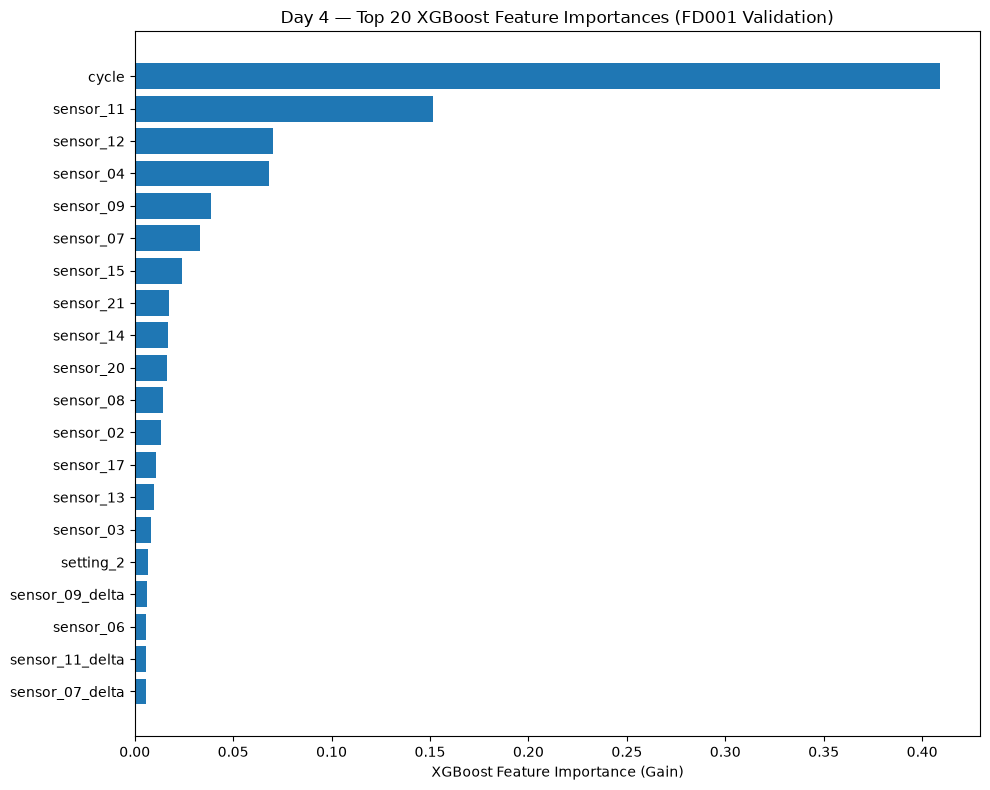

In [4]:
# Feature Importance (Gain-based importance from XGBoost — associative, not causal)
importance_df = pd.DataFrame({
    "feature": features,
    "importance": xgb_model.feature_importances_.astype(float),
}).sort_values("importance", ascending=False).reset_index(drop=True)

assert len(importance_df) == 46
assert importance_df["importance"].notna().all()
assert np.isfinite(importance_df["importance"]).all()

print("Top 15 XGBoost Features:")
print(importance_df.head(15).to_string(index=False))

top_20 = importance_df.head(20).sort_values("importance")
plt.figure(figsize=(10, 8))
plt.barh(top_20["feature"], top_20["importance"])
plt.xlabel("XGBoost Feature Importance (Gain)")
plt.title("Day 4 — Top 20 XGBoost Feature Importances (FD001 Validation)")
plt.tight_layout()
plt.show()

In [5]:
# Persist ml/metrics/day4_rul_comparison.json
evaluation_timestamp = datetime.now(timezone.utc).isoformat()

day4_metrics = {
    "dataset": "NASA C-MAPSS FD001",
    "evaluation_split": "Engine-wise validation",
    "feature_count": len(features),
    "features": features,
    "train_rows": int(len(X_train)),
    "validation_rows": int(len(X_val)),
    "train_engines": int(len(train_engines)),
    "validation_engines": int(len(val_engines)),
    "train_validation_engine_overlap": int(len(train_engines & val_engines)),
    "target": "RUL",
    "random_seed": 42,
    "models": {
        "Dummy Regressor": {
            "hyperparameters": {"strategy": "mean"},
            **dummy_metrics,
        },
        "Random Forest": {
            "hyperparameters": rf_model.get_params(),
            "training_seconds": float(rf_time),
            **rf_metrics,
        },
        "XGBoost": {
            "hyperparameters": xgb_model.get_params(),
            "training_seconds": float(xgb_time),
            **xgb_metrics,
        },
    },
    "feature_importance": importance_df.to_dict(orient="records"),
    "validation_predictions": [
        {
            "unit_number": int(unit),
            "cycle": int(cycle),
            "actual_RUL": float(actual),
            "dummy_prediction": float(dummy_p),
            "random_forest_prediction": float(rf_p),
            "xgboost_prediction": float(xgb_p),
        }
        for unit, cycle, actual, dummy_p, rf_p, xgb_p in zip(
            val_df["unit_number"],
            val_df["cycle"],
            y_val,
            dummy_pred,
            rf_pred,
            xgb_pred,
        )
    ],
    "versions": {
        "python": sys.version.split()[0],
        "scikit_learn": sklearn.__version__,
        "xgboost": xgb.__version__,
        "pandas": pd.__version__,
        "numpy": np.__version__,
    },
    "test_data_used": False,
    "production_model_replaced": False,
    "evaluation_timestamp": evaluation_timestamp,
}

metrics_path = METRICS_DIR / "day4_rul_comparison.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(day4_metrics, f, indent=2)

print("Saved metrics JSON:", metrics_path, "| Size:", metrics_path.stat().st_size, "bytes")

Saved metrics JSON: C:\Users\Vivek Nigam\Desktop\YantraDrishti\ml\metrics\day4_rul_comparison.json | Size: 975529 bytes


In [6]:
# Generate ml/reports/day4_rul_model_comparison.md from computed metrics
mae_diff_pct = (rf_metrics["mae"] - xgb_metrics["mae"]) / rf_metrics["mae"] * 100.0
rmse_diff_pct = (rf_metrics["rmse"] - xgb_metrics["rmse"]) / rf_metrics["rmse"] * 100.0
nasa_diff_pct = (rf_metrics["nasa_score"] - xgb_metrics["nasa_score"]) / rf_metrics["nasa_score"] * 100.0

top10_rows = "\n".join(
    f"| {idx + 1} | `{row['feature']}` | {row['importance']:.6f} |"
    for idx, row in importance_df.head(10).iterrows()
)
zero_imp_features = importance_df[importance_df["importance"] == 0.0]["feature"].tolist()

report_md = f"""# Day 4 — FD001 RUL Model Comparison (Random Forest vs XGBoost)

## Objective
Compare the Day 3 Random Forest RUL baseline against an XGBoost Regressor on the NASA C-MAPSS FD001 dataset using the identical engine-wise validation split and 46-feature contract.

## Methodology
- **Dataset:** NASA C-MAPSS FD001
- **Split Strategy:** Engine-wise 80:20 split (`split_manifest.json`, `random_state=42`)
  - Training: {len(X_train):,} rows across {len(train_engines)} engines
  - Validation: {len(X_val):,} rows across {len(val_engines)} engines
  - Train-Validation Engine Overlap: 0
- **Features:** {len(features)} features (`cycle`, `setting_1..3`, `sensor_01..21`, `sensor_01_delta..sensor_21_delta`); `unit_number` and `RUL` excluded.
- **Models Evaluated:**
  1. `DummyRegressor(strategy="mean")`
  2. `RandomForestRegressor` (`n_estimators=150`, `max_depth=15`, `min_samples_split=5`, `min_samples_leaf=2`, `random_state=42`)
  3. `XGBRegressor` (`n_estimators=500`, `max_depth=4`, `learning_rate=0.03`, `subsample=0.8`, `colsample_bytree=0.8`, `min_child_weight=5`, `reg_lambda=5`, `tree_method="hist"`, `random_state=42`)
- **Evaluation Metrics:** MAE, RMSE, and the asymmetric NASA C-MAPSS Score (which penalizes RUL overestimation more heavily than underestimation).
- **Test Set Isolation:** The test dataset (`test_prepared.csv`) was **not** used for training, tuning, or model selection.
- **Production Model Status:** The Day 3 production artifact (`ml/models/rul_baseline.joblib`) was **not** overwritten or replaced.

## Validation Metrics

| Model | MAE | RMSE | NASA Score | Training Time (s) |
|---|---:|---:|---:|---:|
| Dummy Regressor | {dummy_metrics['mae']:.3f} | {dummy_metrics['rmse']:.3f} | {dummy_metrics['nasa_score']:.3f} | - |
| Random Forest (Day 3 Baseline) | {rf_metrics['mae']:.3f} | {rf_metrics['rmse']:.3f} | {rf_metrics['nasa_score']:.3f} | {rf_time:.2f} |
| XGBoost | {xgb_metrics['mae']:.3f} | {xgb_metrics['rmse']:.3f} | {xgb_metrics['nasa_score']:.3f} | {xgb_time:.2f} |

## Comparison Summary
- **XGBoost vs. Random Forest:**
  - **MAE:** Improved from `{rf_metrics['mae']:.3f}` to `{xgb_metrics['mae']:.3f}` (**{mae_diff_pct:.2f}%** reduction).
  - **RMSE:** Improved from `{rf_metrics['rmse']:.3f}` to `{xgb_metrics['rmse']:.3f}` (**{rmse_diff_pct:.2f}%** reduction).
  - **NASA Score:** Improved from `{rf_metrics['nasa_score']:.3f}` to `{xgb_metrics['nasa_score']:.3f}` (**{nasa_diff_pct:.2f}%** reduction), indicating substantially fewer severe late-prediction / overestimation errors.
  - **Training Speed:** XGBoost (`tree_method="hist"`) trained in `{xgb_time:.2f}s` compared to `{rf_time:.2f}s` for Random Forest.
- **Reproducibility:** The Day 3 Random Forest baseline metrics (`MAE={day3_metrics['mae']:.3f}`, `RMSE={day3_metrics['rmse']:.3f}`, `NASA Score={day3_metrics['nasa_score']:.3f}`) were reproduced exactly.

## Feature Importance Interpretation (XGBoost)
Top 10 features ranked by XGBoost split gain importance:

| Rank | Feature | Importance |
|---:|---|---:|
{top10_rows}

- **Important Note:** Tree-based feature importance measures each feature's relative contribution to reducing training loss within the fitted model. It reflects **model-based statistical association**, **not causal physical relationships**.
- {len(zero_imp_features)} features received `0.0` importance in XGBoost (`{', '.join(zero_imp_features)}`), consistent with constant or near-constant channels in C-MAPSS FD001.

## Limitations
- Evaluation was conducted strictly on the 20-engine FD001 validation split; held-out test set performance was not evaluated.
- Hyperparameters for XGBoost were selected as a clean regularized configuration without exhaustive cross-validated grid search.
- Results are specific to C-MAPSS FD001 (single operating condition, single fault mode) and do not generalize directly to FD002–FD004 without further validation.
- No SHAP local attribution or anomaly detection was performed in this comparison.

## Environment & Versions
- **Python:** `{sys.version.split()[0]}`
- **scikit-learn:** `{sklearn.__version__}`
- **xgboost:** `{xgb.__version__}`
- **pandas:** `{pd.__version__}`
- **numpy:** `{np.__version__}`
- **Evaluation Timestamp (UTC):** `{evaluation_timestamp}`

## Artifacts
- `ml/notebooks/YantraDrishti_Day4_RUL_Model_Comparison.ipynb`
- `ml/metrics/day4_rul_comparison.json`
- `ml/reports/day4_rul_model_comparison.md`
"""

report_path = REPORTS_DIR / "day4_rul_model_comparison.md"
report_path.write_text(report_md, encoding="utf-8")
print("Saved report:", report_path, "| Size:", report_path.stat().st_size, "bytes")

Saved report: C:\Users\Vivek Nigam\Desktop\YantraDrishti\ml\reports\day4_rul_model_comparison.md | Size: 4344 bytes


In [7]:
# Final validation of all Day 4 artifacts
with open(METRICS_DIR / "day4_rul_comparison.json", encoding="utf-8") as f:
    saved_json = json.load(f)

assert saved_json["feature_count"] == 46
assert len(saved_json["features"]) == 46
assert len(saved_json["validation_predictions"]) == 4070
assert len(saved_json["feature_importance"]) == 46
assert saved_json["train_rows"] == 16561
assert saved_json["validation_rows"] == 4070
assert saved_json["train_engines"] == 80
assert saved_json["validation_engines"] == 20
assert saved_json["train_validation_engine_overlap"] == 0
assert saved_json["test_data_used"] is False
assert saved_json["production_model_replaced"] is False

for model_name, m in saved_json["models"].items():
    for metric_key in ("mae", "rmse", "nasa_score"):
        val = m[metric_key]
        assert np.isfinite(val) and val >= 0.0, f"Invalid {metric_key} for {model_name}: {val}"

assert (REPORTS_DIR / "day4_rul_model_comparison.md").is_file()
assert (MODELS_DIR / "rul_baseline.joblib").is_file()

print("ALL DAY 4 DELIVERABLE VALIDATIONS PASSED!")

ALL DAY 4 DELIVERABLE VALIDATIONS PASSED!
